# Who Is On The Other Side? CFTC, Futures Aggressors & Dealer Gamma

Combined positioning (notebooks 03–05) tells you *how crowded* a market is. The flow datasets tell you **who** the crowd
is and **who is taking the other side**. That often matters more than the level itself, because different investors
have different pain thresholds and constraints.

1. **CFTC trader categories:** leveraged funds vs asset managers in Treasuries (the basis trade), and managed money vs
   producers in commodities
2. **Futures aggressors:** is buying in bond futures new conviction or short covering?
3. **Dealer gamma:** which regime options dealers are in, how long regimes last, and whether equity and credit flip together

In [1]:
import sys
from pathlib import Path

from dotenv import load_dotenv

sys.path.insert(0, str(Path.cwd().parent))
load_dotenv(Path.cwd().parent / ".env")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import quantkit as qk

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
qk.set_style()
names = qk.names()

## 1. CFTC trader categories

The weekly Commitments of Traders reports split open interest by trader type. VandaXasset converts contracts to USD and
publishes, per category: `exposure_long`, `exposure_short`, `exposure_net` (all USD mn), weekly `net` change, and trader
counts. The identity `exposure_net = exposure_long − exposure_short` holds exactly.

### The Treasury basis trade

Asset managers hold Treasury **futures** long as a cheap duration substitute. Leveraged funds take the other side: short
futures, long the cash bond, financed in repo. The size of that pair is a financial-stability watchpoint, because a
forced unwind can move Treasury yields abruptly (March 2020 is the example).

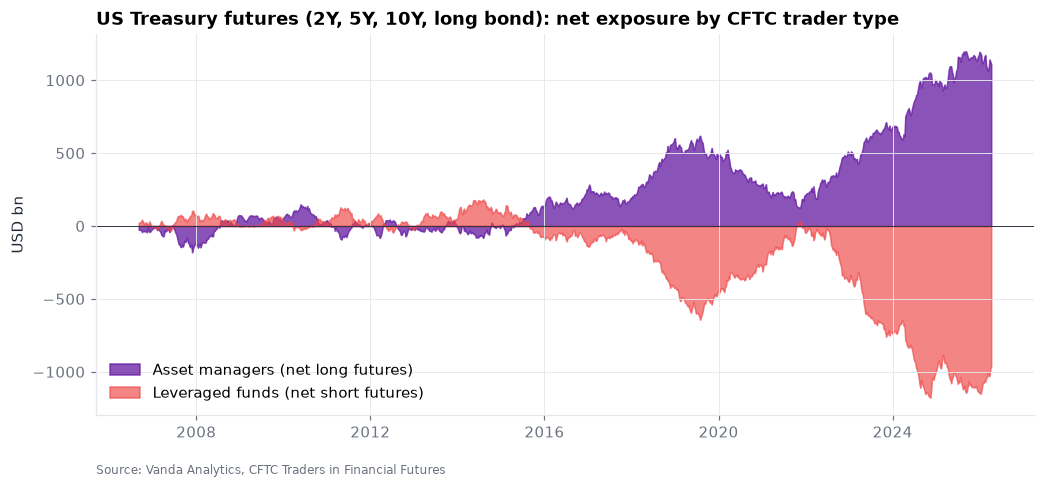

In [2]:
TENORS = {"TU1": "2Y", "FV1": "5Y", "TY1": "10Y", "US1": "Long bond"}
labels = [f"USFIFUTU{c}MIXINS{t}" for c in TENORS for t in ("SPELEV", "SPEASS")]
cftc = qk.load("flow", "global_cftc_positioning_flows", series=labels, metrics="exposure_net")
net = qk.pivot(cftc) / 1_000

lev = net[[l for l in labels if l.endswith("LEV")]].sum(axis=1, min_count=1)
am = net[[l for l in labels if l.endswith("ASS")]].sum(axis=1, min_count=1)

fig, ax = plt.subplots()
ax.fill_between(am.index, am, color=qk.VANDA["purple"], alpha=0.75, label="Asset managers (net long futures)")
ax.fill_between(lev.index, lev, color=qk.VANDA["neg"], alpha=0.65, label="Leveraged funds (net short futures)")
ax.axhline(0, color=qk.VANDA["ink"], lw=0.6)
ax.set_ylabel("USD bn")
ax.set_title("US Treasury futures (2Y, 5Y, 10Y, long bond): net exposure by CFTC trader type")
ax.legend(loc="lower left")
qk.source_note(ax, "Source: Vanda Analytics, CFTC Traders in Financial Futures")
plt.show()

In [3]:
by_tenor = pd.DataFrame({
    tenor: {
        "leveraged funds $bn": net[f"USFIFUTU{code}MIXINSSPELEV"].dropna().iloc[-1],
        "asset managers $bn": net[f"USFIFUTU{code}MIXINSSPEASS"].dropna().iloc[-1],
        "lev. funds: percentile of history": qk.percentile_of_last(net[f"USFIFUTU{code}MIXINSSPELEV"]),
    }
    for code, tenor in TENORS.items()
}).T
print(f"As of {net.index.max():%d %b %Y}")
by_tenor.round(1)

As of 07 Apr 2026


,leveraged funds $bn,asset managers $bn,lev. funds: percentile of history
2Y,-451.1,512.2,3.5
5Y,-268.8,309.4,9.5
10Y,-218.3,246.7,4.7
Long bond,-22.6,42.2,33.2


A **low** percentile for leveraged funds means a historically **large short**: more trade to unwind if funding or
volatility conditions tighten.

### Commodities: managed money vs producers

In commodities the disaggregated report separates **managed money** (CTAs and macro funds, which are trend-sensitive)
from **producers/merchants** (natural hedgers). They are usually on opposite sides: when managed money buys, hedgers
are the ones selling to them.

In [4]:
COMMODITIES = {"GC1": "Gold", "CL1": "WTI crude", "HG1": "Copper", "C1": "Corn", "SI1": "Silver", "NG1": "Natural gas"}
mm_labels = {f"GLCOMFUTU{c}MIXINSSPEMAN": name for c, name in COMMODITIES.items()}
pro_labels = {f"GLCOMFUTU{c}MIXINSCOMPRO": name for c, name in COMMODITIES.items()}
mm = qk.pivot(qk.load("flow", "global_cftc_positioning_flows", series=list(mm_labels), metrics="exposure_net")).rename(columns=mm_labels)
pro = qk.pivot(qk.load("flow", "global_cftc_positioning_flows", series=list(pro_labels), metrics="exposure_net")).rename(columns=pro_labels)

table = pd.DataFrame({
    name: {
        "managed money $bn": mm[name].dropna().iloc[-1] / 1_000,
        "producers $bn": pro[name].dropna().iloc[-1] / 1_000,
        "managed money: percentile of history": qk.percentile_of_last(mm[name]),
        "corr of weekly changes (MM vs producers)": mm[name].diff().corr(pro[name].diff()),
    }
    for name in COMMODITIES.values() if name in mm and name in pro
}).T
print(f"As of {mm.index.max():%d %b %Y}")
table.round(2)

As of 07 Apr 2026


,managed money $bn,producers $bn,managed money: percentile of history,corr of weekly changes (MM vs producers)
Gold,42.90,-10.23,91.53,-0.74
WTI crude,15.57,34.52,64.30,-0.43
Copper,5.40,-11.25,90.74,-0.86
Corn,4.91,-10.93,71.06,-0.93
Silver,3.61,-5.61,66.65,-0.77
Natural gas,-2.48,-0.27,31.88,-0.33


The strongly negative correlations confirm the two groups take opposite sides week after week. The managed-money
**percentile** is the crowding read: near 100 means speculators are as long as they have ever been, with hedgers
correspondingly short.

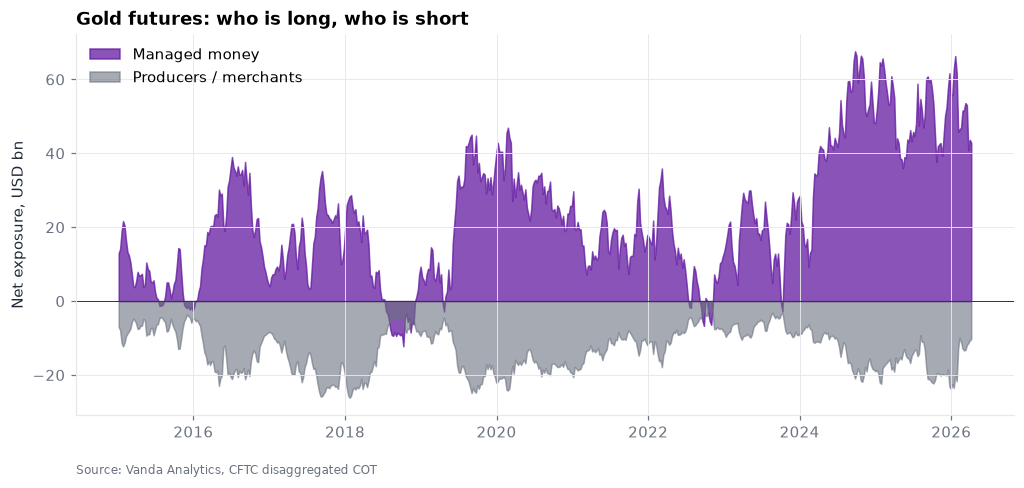

In [5]:
gold = pd.concat({"Managed money": mm["Gold"], "Producers / merchants": pro["Gold"]}, axis=1).loc["2015":] / 1_000
fig, ax = plt.subplots()
ax.fill_between(gold.index, gold["Managed money"], color=qk.VANDA["purple"], alpha=0.75, label="Managed money")
ax.fill_between(gold.index, gold["Producers / merchants"], color=qk.VANDA["sub"], alpha=0.6, label="Producers / merchants")
ax.axhline(0, color=qk.VANDA["ink"], lw=0.6)
ax.set_ylabel("Net exposure, USD bn")
ax.set_title("Gold futures: who is long, who is short")
ax.legend(loc="upper left")
qk.source_note(ax, "Source: Vanda Analytics, CFTC disaggregated COT")
plt.show()

## 2. Futures aggressors: conviction or covering?

For major bond futures, the aggressors dataset classifies each day's aggressive (price-taking) speculative flow into
**opening** and **closing** trades. It holds two exact identities:

* `buy = new_long + closed_short`: buying is either new longs or short covering
* `net = buy − sell = (new_long − closed_long) − (new_short − closed_short)`

The split matters. A rally driven by **new longs** reflects conviction; one driven by **short covering** tends to burn
out once the shorts are flat.

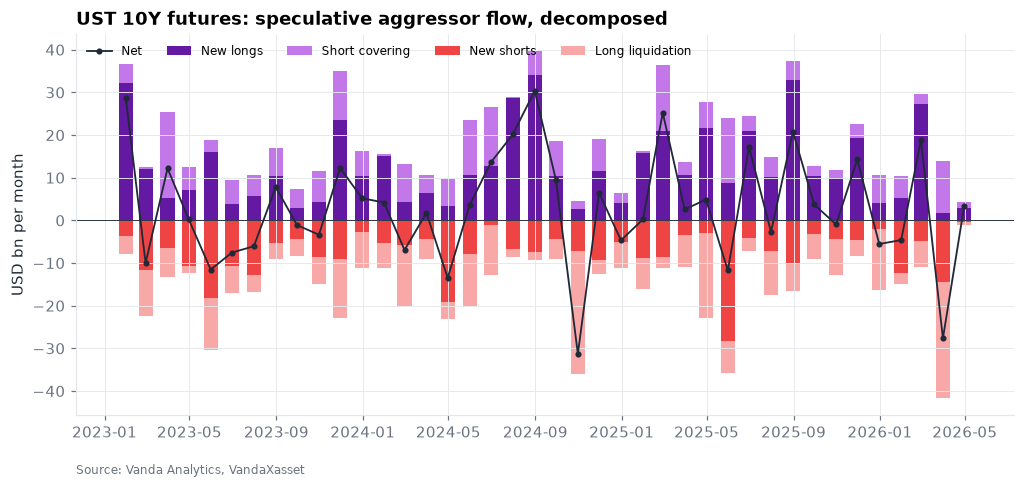

In [6]:
AGGRESSORS = {"USFIFUTUTY1MIXINSSPEAGG": "UST 10Y", "USFIFUTUTU1MIXINSSPEAGG": "UST 2Y", "DEFIFUTURX1MIXINSSPEAGG": "Bund", "GBFIFUTUG1MIXINSSPEAGG": "Gilt"}
agg = qk.load("flow", "global_fixed_income_futures_aggressors", series=list(AGGRESSORS),
              metrics=["new_long_usd", "closed_long_usd", "new_short_usd", "closed_short_usd", "net_usd"])
agg = agg.pivot_table(index="ts", columns=["series_label", "metric"], values="value")

ty = agg["USFIFUTUTY1MIXINSSPEAGG"].resample("ME").sum().loc["2023":] / 1_000
fig, ax = plt.subplots()
ax.bar(ty.index, ty.new_long_usd, width=20, color=qk.VANDA["purple"], label="New longs")
ax.bar(ty.index, ty.closed_short_usd, width=20, bottom=ty.new_long_usd, color=qk.VANDA["lilac"], label="Short covering")
ax.bar(ty.index, -ty.new_short_usd, width=20, color=qk.VANDA["neg"], label="New shorts")
ax.bar(ty.index, -ty.closed_long_usd, width=20, bottom=-ty.new_short_usd, color="#f9a8a8", label="Long liquidation")
ax.plot(ty.index, ty.net_usd, color=qk.VANDA["ink"], marker="o", ms=3, lw=1.2, label="Net")
ax.axhline(0, color=qk.VANDA["ink"], lw=0.6)
ax.set_ylabel("USD bn per month")
ax.set_title("UST 10Y futures: speculative aggressor flow, decomposed")
ax.legend(loc="upper left", ncol=5, fontsize=8)
qk.source_note(ax)
plt.show()

In [7]:
def composition(label: str, months: int = 3) -> pd.Series:
    x = agg[label].loc[agg.index.max() - pd.DateOffset(months=months):].sum()
    buying, selling = x.new_long_usd + x.closed_short_usd, x.new_short_usd + x.closed_long_usd
    return pd.Series({
        "net $bn": x.net_usd / 1_000,
        "buying that was new longs": x.new_long_usd / buying if buying else np.nan,
        "selling that was new shorts": x.new_short_usd / selling if selling else np.nan,
    })


print("Last 3 months")
pd.DataFrame({name: composition(label) for label, name in AGGRESSORS.items()}).T.round(2)

Last 3 months


,net $bn,buying that was new longs,selling that was new shorts
UST 10Y,-10.94,0.62,0.45
UST 2Y,39.30,0.63,0.56
Bund,-8.26,0.43,0.57
Gilt,-0.85,0.32,0.32


## 3. Dealer gamma regimes

Options dealers hedge dynamically. When they are **long gamma** they sell rallies and buy dips, which damps moves. When
they are **short gamma** they must chase the market, which amplifies moves. `us_dealer_gamma_exposure` estimates dealer
gamma (USD mn) for options on SPY, QQQ, HYG and LQD.

In [8]:
GAMMA = {"USEQOPTISPYMIXINSCOMDEA": "SPY", "USEQOPTIQQQMIXINSCOMDEA": "QQQ", "USFIOPTIHYGMIXINSCOMDEA": "HYG", "USFIOPTILQDMIXINSCOMDEA": "LQD"}
gamma = qk.pivot(qk.load("flow", "us_dealer_gamma_exposure", series=list(GAMMA), metrics="exposure_gamma")).rename(columns=GAMMA)


def run_lengths(short: pd.Series) -> pd.Series:
    """Lengths, in observations, of consecutive short-gamma stretches."""
    groups = (short != short.shift()).cumsum()
    return short.groupby(groups).agg(["first", "size"]).query("first")["size"]


regimes = pd.DataFrame({
    name: {
        "latest $bn": s.dropna().iloc[-1] / 1_000,
        "percentile of history": qk.percentile_of_last(s),
        "share of days short gamma": (s.dropna() < 0).mean(),
        "median short-gamma run (days)": run_lengths(s.dropna() < 0).median(),
        "longest short-gamma run (days)": run_lengths(s.dropna() < 0).max(),
    }
    for name, s in gamma.items()
}).T
print(f"As of {gamma.index.max():%d %b %Y}")
regimes.round(2)

As of 10 Apr 2026


,latest $bn,percentile of history,share of days short gamma,median short-gamma run (days),longest short-gamma run (days)
QQQ,0.12,87.93,0.57,3.0,50.0
SPY,0.14,54.57,0.49,2.0,73.0
HYG,-0.22,10.35,0.97,17.0,579.0
LQD,-0.03,18.55,0.75,5.0,282.0


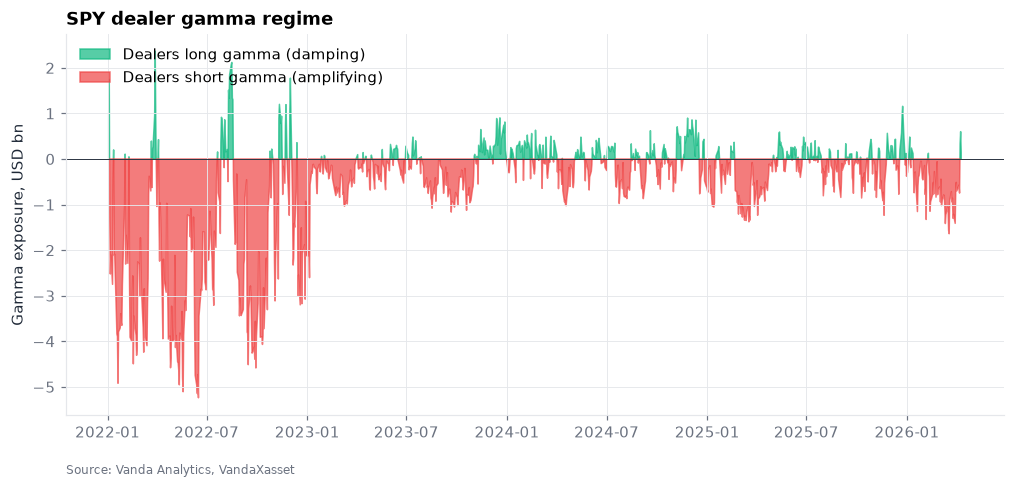

In [9]:
fig, ax = plt.subplots()
g = (gamma["SPY"] / 1_000).loc["2022":]
ax.fill_between(g.index, g, where=g >= 0, color=qk.VANDA["pos"], alpha=0.7, interpolate=True, label="Dealers long gamma (damping)")
ax.fill_between(g.index, g, where=g < 0, color=qk.VANDA["neg"], alpha=0.7, interpolate=True, label="Dealers short gamma (amplifying)")
ax.axhline(0, color=qk.VANDA["ink"], lw=0.6)
ax.set_ylabel("Gamma exposure, USD bn")
ax.set_title("SPY dealer gamma regime")
ax.legend(loc="upper left")
qk.source_note(ax)
plt.show()

Do equity and credit dealers flip regime together? The share of days on which SPY and HYG dealers are in the same
regime, and how often they are short gamma at the same time:

In [10]:
both = gamma[["SPY", "QQQ", "HYG", "LQD"]].dropna()
short = both < 0
pd.DataFrame({
    "same regime as SPY": {c: (short[c] == short["SPY"]).mean() for c in short},
    "short gamma together with SPY": {c: (short[c] & short["SPY"]).mean() for c in short},
}).round(2)

,same regime as SPY,short gamma together with SPY
SPY,1.00,0.49
QQQ,0.78,0.41
HYG,0.50,0.48
LQD,0.56,0.40


A short-gamma regime in both equity and credit options is the setup in which hedging flows reinforce each other across
markets. To test how regimes relate to subsequent volatility, join these series to your own price history.

---
**Next:** `09 - Sector Rotation Across Regions`.